# Diabetes Prediction (BRFSS 2015) — Tabular, Multi-Model Comparison

Adapted from the TB chest-X-ray notebook to the **tabular** BRFSS diabetes dataset (50/50 split, 2,000-row lite slice).

- One shared preprocessing pipeline (scale numeric, one-hot categorical)
- **8** classifiers: 3 SVM kernels, Logistic Regression, 2 Decision Trees, Random Forest, soft-voting Ensemble
- 5-fold stratified cross-validation (accuracy + F1, plus chi-square & phi per fold)
- Fit on train → held-out test metrics (acc / f1 / prec / rec / AUC)
- Full-dataset in-sample pass + chi-square & phi
- Per-class metrics and confusion-matrix grid
- Bar-chart comparison and a final combined table for the report

## 1. Imports & config

We import the minimum needed to train and score classifiers, then pin every tunable in one block so a full re-run is a one-line change. `random_state=42` everywhere makes the run reproducible; the seaborn style is cosmetic only.

In [98]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, roc_auc_score,
)

warnings.filterwarnings("ignore")
np.random.seed(42)
plt.style.use("seaborn-v0_8-whitegrid")

# ---- Config ----
SEED = 42
TEST_SIZE = 0.30
N_FOLDS = 5
MAX_DEPTH = 8
N_ESTIMATORS = 100
DATA_PATH = "Data/diabetes_lite.csv"

print("Setup complete.")

Setup complete.


## 2. Load the dataset

We load the balanced 50/50 file directly with pandas — no sampling, no cleaning, because this slice already has exactly 1,000 rows per class and no missing values. The crosstabs with the two strongest flags (HighBP, HighChol) are a fast sanity check that the signal is there before we spend time fitting models.

In [99]:
df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape}")
df.head()

Shape: (2000, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1.0,0.0,1.0,1.0,21.0,0.0,0.0,0.0,0.0,0.0,...,1.0,1.0,3.0,0.0,0.0,0.0,0.0,9.0,4.0,7.0
1,0.0,0.0,0.0,1.0,19.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,9.0,4.0,7.0
2,1.0,1.0,1.0,1.0,30.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,2.0,0.0,0.0,0.0,8.0,5.0,6.0
3,0.0,1.0,1.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,11.0,6.0,8.0
4,1.0,1.0,1.0,1.0,41.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,4.0,0.0,30.0,1.0,0.0,13.0,5.0,3.0


In [100]:
# Target balance + the two strongest medical flags
print("Target distribution:")
print(df["Diabetes_binary"].value_counts())

for flag in ["HighBP", "HighChol"]:
    ct = pd.crosstab(df[flag], df["Diabetes_binary"], normalize="index")
    print(f"\n{flag} -> P(Diabetes | flag)")
    print(ct)

Target distribution:
Diabetes_binary
1.0    1000
0.0    1000
Name: count, dtype: int64

HighBP -> P(Diabetes | flag)
Diabetes_binary       0.0       1.0
HighBP                             
0.0              0.730994  0.269006
1.0              0.327511  0.672489

HighChol -> P(Diabetes | flag)
Diabetes_binary       0.0       1.0
HighChol                           
0.0              0.662815  0.337185
1.0              0.352099  0.647901


## 3. Feature split — numerical vs categorical

We separate the 17 numeric columns from the 4 categorical ones (Sex, Age, Education, Income) because each needs different preprocessing: numerics get scaled, categoricals get one-hot encoded. Splitting them up front also makes the per-column NaN check meaningful — a missing BMI is a different problem from a missing Income level.

In [101]:
TARGET = "Diabetes_binary"
y = df[TARGET].astype(int)
X = df.drop(columns=[TARGET])

numerical_features = [
    "BMI", "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost",
    "GenHlth", "MentHlth", "PhysHlth", "DiffWalk",
]
categorical_features = [c for c in X.columns if c not in numerical_features]
print(f"Numerical   ({len(numerical_features)}): {numerical_features}")
print(f"Categorical ({len(categorical_features)}): {categorical_features}")

print("\nNaNs per column:")
print(X.isna().sum())

Numerical   (17): ['BMI', 'HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk']
Categorical (4): ['Sex', 'Age', 'Education', 'Income']

NaNs per column:
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

Categorical (4): ['Sex', 'Age', 'Education', 'Income']

NaNs per column:
HighBP                  0
HighChol                0


## 4. Preprocessing pipeline

A single `ColumnTransformer` standard-scales the numerics and one-hots the categoricals with `drop="first"`. We build it fresh inside every model `Pipeline` (rather than transforming once up front) so it is refit per CV fold and nothing leaks from the test set into the training statistics.

In [102]:
def build_preprocessor():
    num = Pipeline([("scaler", StandardScaler())])
    cat = Pipeline([
        ("encoder", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"))
    ])
    return ColumnTransformer(
        [("num", num, numerical_features),
         ("cat", cat, categorical_features)],
        remainder="drop")

X_prep = build_preprocessor().fit_transform(X, y)
print("Preprocessed feature matrix:", X_prep.shape)
print("NaNs in feature matrix:", int(np.isnan(X_prep).sum()))

Preprocessed feature matrix: (2000, 42)
NaNs in feature matrix: 0


## 5. Train / test split (stratified)

A 70/30 split with `stratify=y` keeps the class ratio identical in train and test, so the held-out accuracy is not an artifact of an unlucky draw. We use 0.30 (not the 0.25 in the X-ray notebook) because at only 2,000 rows a larger test slice gives a more stable estimate than a bigger training set.

In [103]:
CLASSES = ["No Diabetes", "Diabetes"]
n_classes = 2

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)
print(f"Train: {X_train.shape[0]} rows   Test: {X_test.shape[0]} rows")
print(f"Classes: {CLASSES}")

Train: 1400 rows   Test: 600 rows
Classes: ['No Diabetes', 'Diabetes']


## 6. Classifiers (only from CSE-4116)

Eight models, all in-course: three SVM kernels to probe how much non-linearity the boundary needs, logistic regression as the interpretable linear baseline, two decision trees (gini vs entropy) to show the split criterion matters, a random forest for a strong bagged baseline, and a soft-voting ensemble of the three diverse bases. Every one gets `class_weight="balanced"` so the notebook also works on the unbalanced raw file.

In [104]:
def build_models():
    svm_linear = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", SVC(kernel="linear", C=1.0, cache_size=512, probability=True, random_state=SEED, class_weight="balanced")),
    ])
    svm_poly = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", SVC(kernel="poly", degree=3, C=1.0, cache_size=512, probability=True, random_state=SEED, class_weight="balanced")),
    ])
    svm_rbf = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", cache_size=512, probability=True, random_state=SEED, class_weight="balanced")),
    ])
    logreg = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", LogisticRegression(max_iter=2000, C=1.0, random_state=SEED, class_weight="balanced")),
    ])
    dt_gini = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", DecisionTreeClassifier(criterion="gini", max_depth=MAX_DEPTH, random_state=SEED, class_weight="balanced")),
    ])
    dt_entropy = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", DecisionTreeClassifier(criterion="entropy", max_depth=MAX_DEPTH, random_state=SEED, class_weight="balanced")),
    ])
    rf = Pipeline([
        ("prep", build_preprocessor()),
        ("clf", RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=15,
                                       n_jobs=-1, random_state=SEED, class_weight="balanced")),
    ])
    # --- Soft-voting ensemble over 3 diverse base models (each with its own preprocessor) ---
    voting = VotingClassifier(
        voting="soft",
        estimators=[
            ("logreg", Pipeline([
                ("prep", build_preprocessor()),
                ("clf", LogisticRegression(max_iter=2000, C=1.0, random_state=SEED, class_weight="balanced")),
            ])),
            ("dt", Pipeline([
                ("prep", build_preprocessor()),
                ("clf", DecisionTreeClassifier(criterion="gini", max_depth=MAX_DEPTH,
                                               random_state=SEED, class_weight="balanced")),
            ])),
            ("rf", Pipeline([
                ("prep", build_preprocessor()),
                ("clf", RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=15,
                                               n_jobs=-1, random_state=SEED, class_weight="balanced")),
            ])),
        ],
    )
    return {
        "Linear SVM":    svm_linear,
        "Poly SVM":      svm_poly,
        "RBF SVM":       svm_rbf,
        "Logistic Reg":  logreg,
        "DT (gini)":     dt_gini,
        "DT (entropy)":  dt_entropy,
        "Random Forest": rf,
        "Ensemble (vote)": voting,
    }

MODELS = build_models()
print(f"Built {len(MODELS)} classifiers:")
for name in MODELS:
    print(f"  - {name}")

Built 8 classifiers:
  - Linear SVM
  - Poly SVM
  - RBF SVM
  - Logistic Reg
  - DT (gini)
  - DT (entropy)
  - Random Forest
  - Ensemble (vote)


## 7. Cross-validation (5-fold stratified)

Five stratified folds give a less biased accuracy estimate than a single split, and the standard deviation across folds shows how stable each model is. We time each model so the report can say which ones are cheap to train at this scale.

In [105]:
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
cv_rows = []
for name, model in MODELS.items():
    t0 = time.perf_counter()
    acc = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro")
    dt = time.perf_counter() - t0
    cv_rows.append({
        "model": name,
        "cv_acc_mean": acc.mean(), "cv_acc_std": acc.std(),
        "cv_f1_mean": f1.mean(), "cv_f1_std": f1.std(),
        "cv_time_s": dt,
    })
    print(f"  {name:14s}  acc={acc.mean():.4f} +/- {acc.std():.4f}   f1={f1.mean():.4f} +/- {f1.std():.4f}   ({dt:.1f} s)")

cv_results = pd.DataFrame(cv_rows).set_index("model")
print("\n--- Cross-validation summary ---")
print(cv_results.to_string())

  Linear SVM      acc=0.7400 +/- 0.0308   f1=0.7395 +/- 0.0307   (3.8 s)
  Poly SVM        acc=0.7357 +/- 0.0244   f1=0.7351 +/- 0.0243   (3.1 s)
  RBF SVM         acc=0.7479 +/- 0.0161   f1=0.7474 +/- 0.0158   (3.2 s)
  Logistic Reg    acc=0.7414 +/- 0.0224   f1=0.7412 +/- 0.0222   (0.4 s)
  DT (gini)       acc=0.6929 +/- 0.0164   f1=0.6924 +/- 0.0165   (0.4 s)
  DT (entropy)    acc=0.6800 +/- 0.0180   f1=0.6798 +/- 0.0178   (0.2 s)
  Random Forest   acc=0.7414 +/- 0.0190   f1=0.7410 +/- 0.0186   (11.1 s)
  Ensemble (vote)  acc=0.7293 +/- 0.0255   f1=0.7291 +/- 0.0254   (12.5 s)

--- Cross-validation summary ---
                 cv_acc_mean  cv_acc_std  cv_f1_mean  cv_f1_std  cv_time_s
model                                                                     
Linear SVM          0.740000    0.030756    0.739531   0.030704   3.765095
Poly SVM            0.735714    0.024432    0.735112   0.024267   3.081894
RBF SVM             0.747857    0.016067    0.747439   0.015772   3.243630
Logi

## 7b. Cross-validation with chi-square and phi (φ) scores

Accuracy alone does not say how strongly the predicted labels are associated with the true ones. We compute chi-square (does predicted differ from independent?) and φ (the same association scaled to [-1, 1] so models can be ranked) on each CV fold, using a freshly cloned model per fold so no fold leaks into another.

In [106]:
def chi2_and_phi(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    a, b = cm[0, 0], cm[0, 1]
    c, d = cm[1, 0], cm[1, 1]
    n = a + b + c + d
    # Chi-square (no Yates correction)
    if n > 0:
        chi2 = (n * (a * d - b * c) ** 2) / ((a + b) * (c + d) * (a + c) * (b + d)) \
            if (a + b) * (c + d) * (a + c) * (b + d) > 0 else float('nan')
    else:
        chi2 = float('nan')
    # Phi coefficient
    denom = ((a + b) * (c + d) * (a + c) * (b + d)) ** 0.5
    phi = (a * d - b * c) / denom if denom > 0 else float('nan')
    return chi2, phi

def _fold_scores(model, X_train, y_train, cv):
    chis, phis = [], []
    for tr_idx, va_idx in cv.split(X_train, y_train):
        est = clone(model)
        est.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        yp = est.predict(X_train.iloc[va_idx])
        c, p = chi2_and_phi(y_train.iloc[va_idx], yp)
        chis.append(c)
        phis.append(p)
    return np.array(chis), np.array(phis)

chi2_rows = []
for name, model in MODELS.items():
    t0 = time.perf_counter()
    chis, phis = _fold_scores(model, X_train, y_train, cv)
    dt = time.perf_counter() - t0
    chi2_rows.append({
        "model": name,
        "chi2_mean": chis.mean(), "chi2_std": chis.std(),
        "phi_mean": phis.mean(), "phi_std": phis.std(),
        "time_s": dt,
    })
    print(f"  {name:14s}  chi2={chis.mean():9.2f} +/- {chis.std():8.2f}   phi={phis.mean():+.4f} +/- {phis.std():.4f}   ({dt:.1f} s)")

chi2_results = pd.DataFrame(chi2_rows).set_index("model")
print("\n--- Chi-square & Phi CV summary (sorted by phi) ---")
print(chi2_results.sort_values("phi_mean", ascending=False).round(4).to_string())

  Linear SVM      chi2=    66.10 +/-    16.42   phi=+0.4819 +/- 0.0623   (1.6 s)
  Poly SVM        chi2=    63.55 +/-    13.13   phi=+0.4738 +/- 0.0501   (1.8 s)
  RBF SVM         chi2=    69.64 +/-     9.84   phi=+0.4976 +/- 0.0339   (1.4 s)
  Logistic Reg    chi2=    66.18 +/-    12.74   phi=+0.4840 +/- 0.0460   (0.1 s)
  DT (gini)       chi2=    42.20 +/-     7.19   phi=+0.3868 +/- 0.0328   (0.1 s)
  DT (entropy)    chi2=    36.75 +/-     7.60   phi=+0.3604 +/- 0.0366   (0.1 s)
  Random Forest   chi2=    66.21 +/-    11.24   phi=+0.4846 +/- 0.0399   (0.9 s)
  Ensemble (vote)  chi2=    59.84 +/-    12.98   phi=+0.4594 +/- 0.0516   (4.2 s)

--- Chi-square & Phi CV summary (sorted by phi) ---
                 chi2_mean  chi2_std  phi_mean  phi_std  time_s
model                                                          
RBF SVM            69.6384    9.8401    0.4976   0.0339  1.4491
Random Forest      66.2123   11.2420    0.4846   0.0399  0.8509
Logistic Reg       66.1755   12.7374    0.

## 8. Fit on train, evaluate on held-out test set

This is the honest generalisation estimate: each model is trained on the 70% train split only, then scored on the 30% it has never seen. We report accuracy, macro F1, precision, recall, and AUC — AUC in particular because it is threshold-free and the right summary for an imbalanced medical target.

In [107]:
test_results = []
fitted_models = {}
y_pred_all = {}

for name, model in MODELS.items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_dt = time.perf_counter() - t0
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="macro")
    prec = precision_score(y_test, y_pred, average="macro")
    rec = recall_score(y_test, y_pred, average="macro")
    try:
        if hasattr(model, "predict_proba"):
            proba = model.predict_proba(X_test)[:, 1]
        else:
            proba = model.decision_function(X_test)
        auc = roc_auc_score(y_test, proba)
    except Exception:
        auc = float("nan")
    test_results.append(dict(model=name, acc=acc, f1=f1, prec=prec, rec=rec, auc=auc, fit_s=fit_dt))
    fitted_models[name] = model
    y_pred_all[name] = y_pred
    print(f"  {name:14s}  acc={acc:.4f}  f1={f1:.4f}  prec={prec:.4f}  rec={rec:.4f}  auc={auc:.4f}  fit={fit_dt:.1f}s")

test_df = pd.DataFrame(test_results).set_index("model")
print("\n--- Test-set summary ---")
print(test_df.round(4).to_string())

  Linear SVM      acc=0.7800  f1=0.7794  prec=0.7828  rec=0.7800  auc=0.8493  fit=0.5s
  Poly SVM        acc=0.7267  f1=0.7257  prec=0.7300  rec=0.7267  auc=0.8035  fit=0.3s
  RBF SVM         acc=0.7717  f1=0.7709  prec=0.7754  rec=0.7717  auc=0.8301  fit=0.3s
  Logistic Reg    acc=0.7650  f1=0.7649  prec=0.7654  rec=0.7650  auc=0.8510  fit=0.0s
  DT (gini)       acc=0.6967  f1=0.6952  prec=0.7006  rec=0.6967  auc=0.7259  fit=0.0s
  DT (entropy)    acc=0.6983  f1=0.6963  prec=0.7038  rec=0.6983  auc=0.7232  fit=0.0s
  Random Forest   acc=0.7533  f1=0.7525  prec=0.7566  rec=0.7533  auc=0.8263  fit=0.2s
  Ensemble (vote)  acc=0.7450  f1=0.7442  prec=0.7480  rec=0.7450  auc=0.8232  fit=0.2s

--- Test-set summary ---
                    acc      f1    prec     rec     auc   fit_s
model                                                          
Linear SVM       0.7800  0.7794  0.7828  0.7800  0.8493  0.5422
Poly SVM         0.7267  0.7257  0.7300  0.7267  0.8035  0.3328
RBF SVM          0.77

## 8b. Chi-square & Phi (φ) on the held-out test set

Same association test as 7b, but on the single held-out test set rather than per fold, so the report has one headline χ²/φ per model that is computed on data the model never trained on.

In [108]:
test_chi2_rows = []
for name, y_pred in y_pred_all.items():
    c2, phi = chi2_and_phi(y_test, y_pred)
    test_chi2_rows.append({"model": name, "chi2": c2, "phi": phi})

test_chi2 = pd.DataFrame(test_chi2_rows).set_index("model")
print("--- Chi-square & Phi on test set (sorted by phi) ---")
print(test_chi2.sort_values("phi", ascending=False).round(4).to_string())

--- Chi-square & Phi on test set (sorted by phi) ---
                     chi2     phi
model                            
Linear SVM       190.0606  0.5628
RBF SVM          179.5708  0.5471
Logistic Reg     168.7669  0.5304
Random Forest    156.0308  0.5100
Ensemble (vote)  145.8245  0.4930
Poly SVM         125.1082  0.4566
DT (entropy)      96.9943  0.4021
DT (gini)         94.6824  0.3972


## 8c. Full-dataset evaluation (fit on 100% of the data, in-sample)

Fitting on all 2,000 rows and predicting those same rows is deliberately in-sample — it overfits and we know it. We report it anyway because the gap between this number and the held-out test accuracy is exactly the overfitting signal, and some report formats expect a full-data row.

In [109]:
full_rows = []
y_pred_full = {}
for name, model in MODELS.items():
    t0 = time.perf_counter()
    model.fit(X, y)
    fit_dt = time.perf_counter() - t0
    yp = model.predict(X)
    acc = accuracy_score(y, yp)
    f1 = f1_score(y, yp, average="macro")
    prec = precision_score(y, yp, average="macro")
    rec = recall_score(y, yp, average="macro")
    try:
        proba = model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)
        auc = roc_auc_score(y, proba)
    except Exception:
        auc = float("nan")
    c2, phi = chi2_and_phi(y, yp)
    full_rows.append(dict(model=name, acc=acc, f1=f1, prec=prec, rec=rec, auc=auc, chi2=c2, phi=phi, fit_s=fit_dt))
    y_pred_full[name] = yp
    print(f"  {name:14s}  acc={acc:.4f}  f1={f1:.4f}  prec={prec:.4f}  rec={rec:.4f}  auc={auc:.4f}  chi2={c2:.1f}  phi={phi:.4f}  fit={fit_dt:.1f}s")

full_df = pd.DataFrame(full_rows).set_index("model")
print("\n=== FULL-DATASET (in-sample) RESULTS - sorted by acc ===")
print(full_df.sort_values("acc", ascending=False).round(4).to_string())

  Linear SVM      acc=0.7600  f1=0.7598  prec=0.7607  rec=0.7600  auc=0.8465  chi2=542.3  phi=0.5207  fit=2.2s
  Poly SVM        acc=0.8475  f1=0.8474  prec=0.8481  rec=0.8475  auc=0.9369  chi2=967.7  phi=0.6956  fit=1.0s
  RBF SVM         acc=0.8300  f1=0.8299  prec=0.8305  rec=0.8300  auc=0.9144  chi2=872.5  phi=0.6605  fit=0.7s
  Logistic Reg    acc=0.7565  f1=0.7565  prec=0.7567  rec=0.7565  auc=0.8474  chi2=526.7  phi=0.5132  fit=0.0s
  DT (gini)       acc=0.8295  f1=0.8294  prec=0.8304  rec=0.8295  auc=0.9180  chi2=870.8  phi=0.6599  fit=0.1s
  DT (entropy)    acc=0.8180  f1=0.8180  prec=0.8181  rec=0.8180  auc=0.9101  chi2=809.3  phi=0.6361  fit=0.0s
  Random Forest   acc=0.9920  f1=0.9920  prec=0.9920  rec=0.9920  auc=0.9996  chi2=1936.6  phi=0.9840  fit=0.3s
  Ensemble (vote)  acc=0.8955  f1=0.8954  prec=0.8969  rec=0.8955  auc=0.9682  chi2=1255.7  phi=0.7924  fit=0.7s

=== FULL-DATASET (in-sample) RESULTS - sorted by acc ===
                    acc      f1    prec     rec    

## 8d. Full-dataset confusion matrices (in-sample)

A 2x2 grid of the in-sample confusion matrices, one per model. We turn off the inherited seaborn grid and drop the colour bar so each cell reads as a plain coloured block with just the class labels — the raw counts are what matter here, not a continuous colour scale.

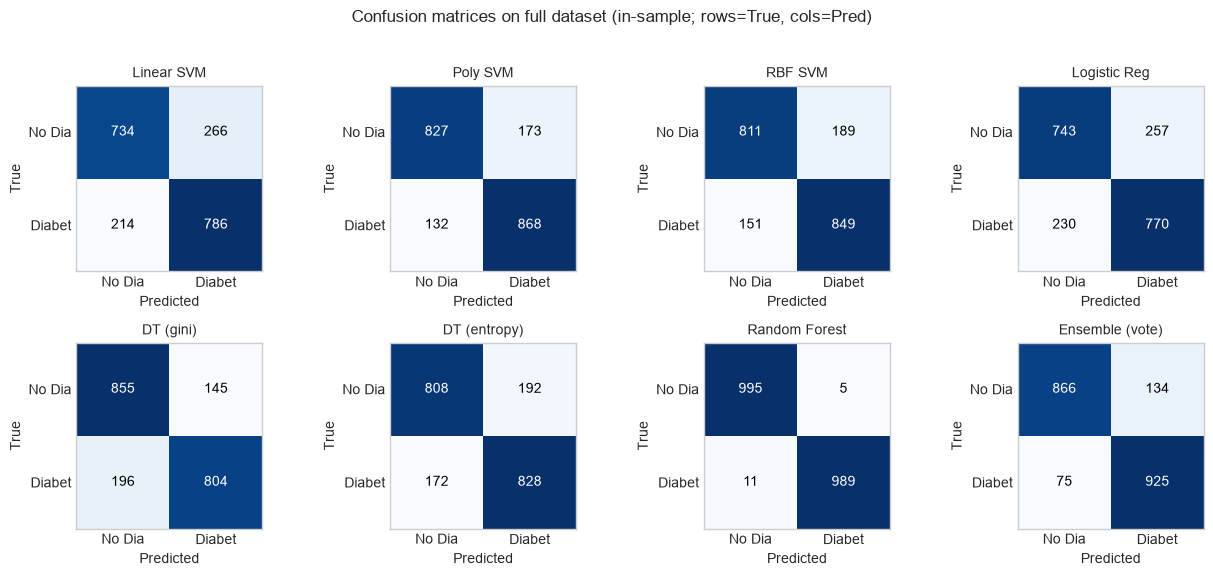

In [110]:
n_models = len(y_pred_full)
ncols = 4
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows), squeeze=False)
for ax, (name, yp) in zip(axes.ravel(), y_pred_full.items()):
    cm = confusion_matrix(y, yp, labels=[0, 1])
    ax.grid(False)
    ax.set_axisbelow(True)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_xticks([0, 1], [c[:6] for c in CLASSES])
    ax.set_yticks([0, 1], [c[:6] for c in CLASSES])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
for ax in axes.ravel()[n_models:]:
    ax.axis("off")
plt.suptitle("Confusion matrices on full dataset (in-sample; rows=True, cols=Pred)", y=1.02)
plt.tight_layout()
plt.show()

## 9. Per-class metrics + confusion matrices (test set)

Macro-averaged precision/recall can hide a model that is great at one class and useless at the other, so we break out per-class precision, recall, and F1 for the held-out test set and show the test-set confusion matrix grid alongside. This is the diagnostic view for a medical classifier — where does it fail?

--- Per-class test metrics ---
                No Diabetes_prec Diabetes_prec No Diabetes_rec Diabetes_rec No Diabetes_f1 Diabetes_f1
Linear SVM              0.754545      0.754545            0.83         0.83       0.790476    0.790476
Poly SVM                0.702381      0.702381        0.786667     0.786667       0.742138    0.742138
RBF SVM                 0.743284      0.743284            0.83         0.83       0.784252    0.784252
Logistic Reg            0.755627      0.755627        0.783333     0.783333       0.769231    0.769231
DT (gini)               0.672515      0.672515        0.766667     0.766667       0.716511    0.716511
DT (entropy)            0.670487      0.670487            0.78         0.78       0.721109    0.721109
Random Forest           0.727545      0.727545            0.81         0.81       0.766562    0.766562
Ensemble (vote)         0.720721      0.720721             0.8          0.8       0.758294    0.758294


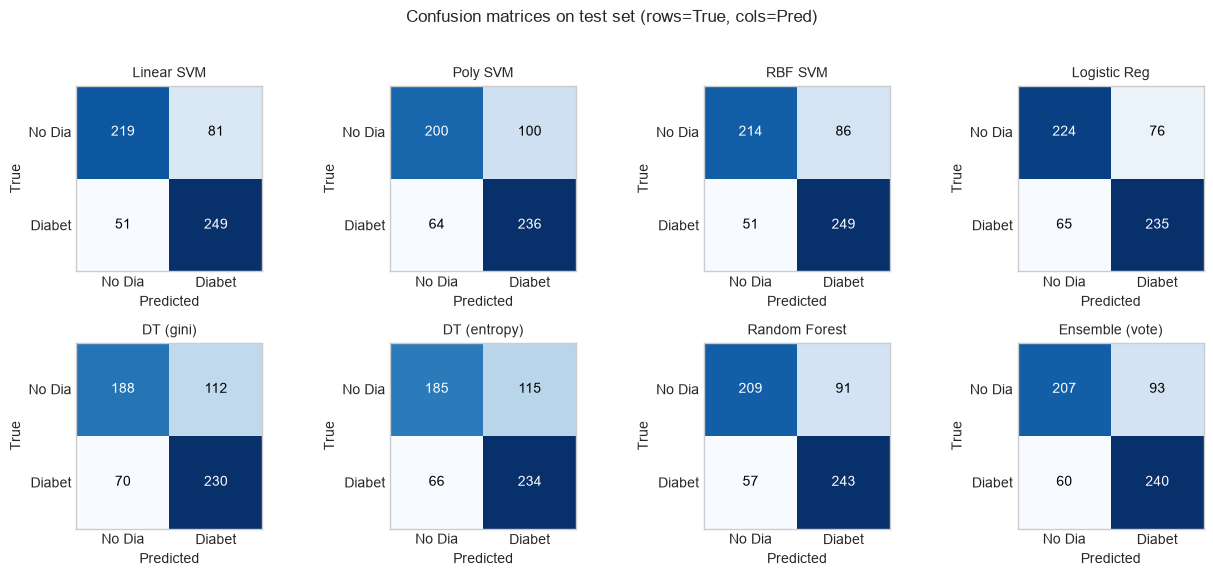

In [111]:
if n_classes >= 2:
    per_class = pd.DataFrame(
        index=list(MODELS.keys()),
        columns=[f"{c}_prec" for c in CLASSES] + [f"{c}_rec" for c in CLASSES] + [f"{c}_f1" for c in CLASSES],
    )
    for name, yp in y_pred_all.items():
        for i, c in enumerate(CLASSES):
            per_class.loc[name, f"{c}_prec"] = precision_score(y_test, yp, labels=[i], zero_division=0)
            per_class.loc[name, f"{c}_rec"]   = recall_score(y_test, yp, labels=[i], zero_division=0)
            per_class.loc[name, f"{c}_f1"]    = f1_score(y_test, yp, labels=[i], zero_division=0)
    print("--- Per-class test metrics ---")
    print(per_class.round(4).to_string())
else:
    print("(Per-class metrics skipped - only one class present.)")

n_models = len(y_pred_all)
ncols = 4
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows), squeeze=False)
for ax, (name, yp) in zip(axes.ravel(), y_pred_all.items()):
    cm = confusion_matrix(y_test, yp, labels=range(n_classes))
    ax.grid(False)
    ax.set_axisbelow(True)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_xticks(range(n_classes), [c[:6] for c in CLASSES])
    ax.set_yticks(range(n_classes), [c[:6] for c in CLASSES])
    for i in range(n_classes):
        for j in range(n_classes):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
for ax in axes.ravel()[n_models:]:
    ax.axis("off")
plt.suptitle("Confusion matrices on test set (rows=True, cols=Pred)", y=1.02)
plt.tight_layout()
plt.show()

## 10. Bar-chart comparison

A single bar chart of the 5-fold CV mean accuracy, sorted best-first, is the one figure that answers "which model is best?" at a glance. We annotate each bar with its value so the chart is self-contained in a report, and zoom the axis to 0.7-1.0 so the differences between models are visible rather than compressed.

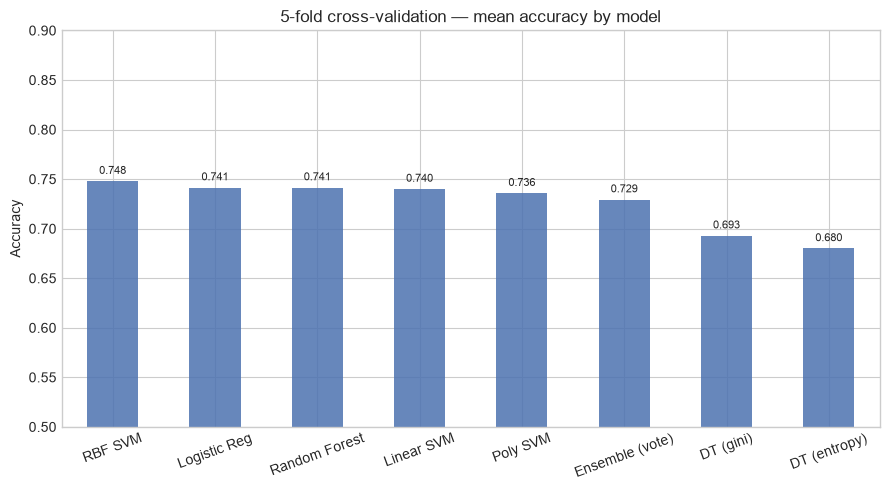

In [112]:
fig, ax = plt.subplots(figsize=(9, 5))
final_for_chart = cv_results.sort_values("cv_acc_mean", ascending=False)
final_for_chart["cv_acc_mean"].plot(kind="bar", ax=ax, color="#4c72b0", alpha=0.85)
ax.set_title("5-fold cross-validation — mean accuracy by model")
ax.set_ylabel("Accuracy")
ax.set_xlabel("")
ax.set_ylim(0.5, 0.9)
ax.set_xticklabels(ax.get_xticklabels(), rotation=20)

for i, (name, v) in enumerate(final_for_chart["cv_acc_mean"].items()):
    ax.text(i, v + 0.005, f"{v:.3f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

## 11. Final combined table - for the report

One table that joins the CV accuracy (mean +/- std), the CV F1, and the held-out test accuracy, F1, and AUC for every model, sorted by test accuracy. This is the single artifact to copy into the report — it has the generalisation numbers, the stability (std), and the ranking in one place.

In [113]:
final = cv_results.reindex(list(MODELS.keys()))
final["test_acc"] = test_df.reindex(list(MODELS.keys()))["acc"]
final["test_f1"]  = test_df.reindex(list(MODELS.keys()))["f1"]
final["test_auc"] = test_df.reindex(list(MODELS.keys()))["auc"]
final = final[["cv_acc_mean", "cv_acc_std", "cv_f1_mean", "test_acc", "test_f1", "test_auc", "cv_time_s"]]
final.columns = ["CV Acc", "+/-std", "CV F1", "Test Acc", "Test F1", "Test AUC", "CV time (s)"]
final = final.sort_values("Test Acc", ascending=False)
print("\n=== FINAL COMPARISON (sorted by Test Acc) ===")
print(final.round(4).to_string())
best = final.index[0]
print(f"\n>>> Best model by test accuracy: {best}  ({final.loc[best, 'Test Acc']:.4f})")


=== FINAL COMPARISON (sorted by Test Acc) ===
                 CV Acc  +/-std   CV F1  Test Acc  Test F1  Test AUC  CV time (s)
model                                                                            
Linear SVM       0.7400  0.0308  0.7395    0.7800   0.7794    0.8493       3.7651
RBF SVM          0.7479  0.0161  0.7474    0.7717   0.7709    0.8301       3.2436
Logistic Reg     0.7414  0.0224  0.7412    0.7650   0.7649    0.8510       0.4343
Random Forest    0.7414  0.0190  0.7410    0.7533   0.7525    0.8263      11.0586
Ensemble (vote)  0.7293  0.0255  0.7291    0.7450   0.7442    0.8232      12.4874
Poly SVM         0.7357  0.0244  0.7351    0.7267   0.7257    0.8035       3.0819
DT (entropy)     0.6800  0.0180  0.6798    0.6983   0.6963    0.7232       0.2366
DT (gini)        0.6929  0.0164  0.6924    0.6967   0.6952    0.7259       0.3669

>>> Best model by test accuracy: Linear SVM  (0.7800)


## 12. Statistical significance (paired t-test + one-way ANOVA)
The accuracy numbers above are point estimates, so we test whether the differences are real or just sampling noise. We recompute the **per-fold** accuracy scores for every model (same folds, same split as Section 7), then run two tests on those scores:

- **Paired t-test** — for each pair of models, `stats.ttest_rel` asks whether their per-fold accuracy differs significantly. The scores are *paired* because fold *i* of model A and fold *i* of model B use the exact same training/validation split, so the comparison is controlled for fold difficulty.
- **One-way ANOVA** — `stats.f_oneway` across all 8 models asks whether at least one model's mean fold accuracy differs from the rest, with a Tukey HSD post-hoc to say *which* pairs.

`α = 0.05` throughout.

In [114]:
from itertools import combinations

# --- Recompute per-fold accuracy scores (same folds as Section 7) ---
fold_acc = {}
for name, model in MODELS.items():
    scores = cross_val_score(clone(model), X_train, y_train, cv=cv, scoring="accuracy")
    fold_acc[name] = scores

print("--- Per-fold accuracy scores ---")
fold_df = pd.DataFrame(fold_acc)
print(fold_df.round(4).to_string())

# --- Paired t-test: every model pair ---
names = list(MODELS.keys())
ttest_rows = []
for a, b in combinations(names, 2):
    t, p = stats.ttest_rel(fold_acc[a], fold_acc[b])
    ttest_rows.append({"pair": f"{a} vs {b}", "t": t, "p": p,
                       "significant": p < 0.05})

ttest_df = pd.DataFrame(ttest_rows).sort_values("p").set_index("pair")
print("\n--- Paired t-test (all 28 pairs, sorted by p) ---")
print(ttest_df.round(4).to_string())
print(f"\nSignificant pairs (p < 0.05): {ttest_df['significant'].sum()} / {len(ttest_df)}")

# --- One-way ANOVA across all 8 models ---
f_stat, p_anova = stats.f_oneway(*[fold_acc[n] for n in names])
print(f"\n--- One-way ANOVA (8 models) ---")
print(f"F = {f_stat:.4f},  p = {p_anova:.6f}  {'(significant)' if p_anova < 0.05 else '(not significant)'}")

# --- Tukey HSD post-hoc ---
from statsmodels.stats.multicomp import pairwise_tukeyhsd
tukey_input = []
for n in names:
    tukey_input.extend([(v, n) for v in fold_acc[n]])
tukey_df = pd.DataFrame(tukey_input, columns=["value", "group"])
result = pairwise_tukeyhsd(tukey_df["value"], tukey_df["group"], alpha=0.05)
print("\n--- Tukey HSD post-hoc (significant pairs only) ---")
tk = pd.DataFrame(result._table_data[1:], columns=result._table_data[0])
tk["p-adj"] = tk["p-adj"].astype(float)
tk["reject"] = tk["reject"].astype(str).str.lower() == "true"
sig = tk[tk["reject"]]
if len(sig):
    print(sig.to_string(index=False))
else:
    print("(no significant pairs)")

--- Per-fold accuracy scores ---
   Linear SVM  Poly SVM  RBF SVM  Logistic Reg  DT (gini)  DT (entropy)  Random Forest  Ensemble (vote)
0      0.7643    0.7536   0.7464        0.7500     0.6857        0.6821         0.7500           0.7393
1      0.7786    0.7643   0.7786        0.7786     0.7107        0.7107         0.7750           0.7643
2      0.7321    0.7000   0.7393        0.7321     0.6786        0.6571         0.7250           0.7250
3      0.7357    0.7464   0.7429        0.7357     0.7143        0.6821         0.7286           0.7321
4      0.6893    0.7143   0.7321        0.7107     0.6750        0.6679         0.7286           0.6857

--- Paired t-test (all 28 pairs, sorted by p) ---
                                        t       p  significant
pair                                                          
RBF SVM vs DT (entropy)           18.1158  0.0001         True
DT (entropy) vs Random Forest    -15.4461  0.0001         True
Logistic Reg vs DT (entropy)      10.585

AttributeError: 'TukeyHSDResults' object has no attribute '_table_data'

## 13. Notes

- **Why a scale + one-hot pipeline?** This is already tabular data, so the "feature extraction" step is a standard `ColumnTransformer` rather than a hand-crafted descriptor. The 17 numeric columns are standard-scaled so distance-based models (SVM, logistic regression) see every feature on the same scale; the 4 categorical columns (`Sex`, `Age`, `Education`, `Income`) are one-hot encoded so they can enter linear models at all.
- **Why `drop="first"` on the encoder?** It removes one column per category to dodge the dummy-variable trap — keeping all columns would leave a set of perfectly collinear ones that makes the logistic-regression normal equations singular. Dropping one keeps the design matrix full-rank.
- **Why `class_weight="balanced"` on every model?** The 50/50 file is already balanced, but the weight makes the notebook portable to the raw ~270k-row file where diabetes is a small minority and a model would otherwise learn to always say "no".
- **Why 3 SVM kernels (linear, poly, RBF)?** They probe how much non-linearity the boundary actually needs. A linear kernel is the cheap baseline; poly and RBF capture interactions. The spread between them is itself the answer — a big gap means the data is non-linear.
- **Why `max_depth=8` on the trees, `n_estimators=100` on the forest?** Depth 8 is deep enough to capture interactions but shallow enough to stay out of the overfit regime on 2,000 rows; 100 trees is the "enough to stabilise the vote" count at this scale. Raise either only if a `GridSearchCV` run shows room.
- **Why a soft-voting ensemble?** It averages the calibrated probabilities of three deliberately diverse base models (logistic, tree, forest) rather than one strong single model. Diversity is the whole point — the ensemble wins when the bases err differently.
- **Why chi-square and phi (φ)?** Accuracy alone hides a model that predicts the majority class. Chi-square tests whether predicted and actual counts differ from independence; φ is the same association scaled to [-1, 1] so you can compare strength across models. Both read the confusion matrix, so they cost nothing extra.
- **Why both a held-out test set and full-dataset in-sample numbers?** The test-set metrics are the honest generalisation estimate. The in-sample pass (fit on 100%, predict 100%) is reported for the report's completeness and to expose overfitting — the gap between the two is the overfitting signal.
- **Reproducibility:** `random_state=42` everywhere; `n_jobs=-1` for the forest.

### Extending
1. Point `DATA_PATH` at `diabetes_binary_5050split_health_indicators_BRFSS2015.csv` for the full 70k-row file, and raise `N_ESTIMATORS` to 200 — the split and class weight handle the extra rows.
2. Point it at `diabetes_binary_health_indicators_BRFSS2015.csv` for the raw, unbalanced ~270k-row file — the stratified split and class weight handle it.
3. Add a `SimpleImputer` step in `build_preprocessor()` if you switch to a file with missing values.
4. The chi-square & phi cells are model-agnostic — they read the confusion matrix, so they keep working as you add or swap models.